<center><h1>Last_First_HW5</h1></center>
<br>
<br>

Name: 
<br>
Github Username: 
<br>
USC ID: 

## 1. Decision Trees as Interpretable Models

Import packages

In [83]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold, cross_val_score, GridSearchCV
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [7]:
df = pd.read_csv("diagnosis.data", sep="\t", header=None, encoding="utf-16")

cols = ["Temperature", "Nausea", "Lumbar Pain", "Urine Pushing", "Micturition Pain", "Urethra Burning", "Bladder Inflammation", "Nephritis"]
df.columns = cols

df["Temperature"] = df["Temperature"].astype(str).str.replace(",", ".", regex=False).astype(float)
for col in cols[1:]:
    df[col] = df[col].astype(str).str.strip().map({"yes": 1, "no": 0})
df.head()

,Temperature,Nausea,Lumbar Pain,Urine Pushing,Micturition Pain,Urethra Burning,Bladder Inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

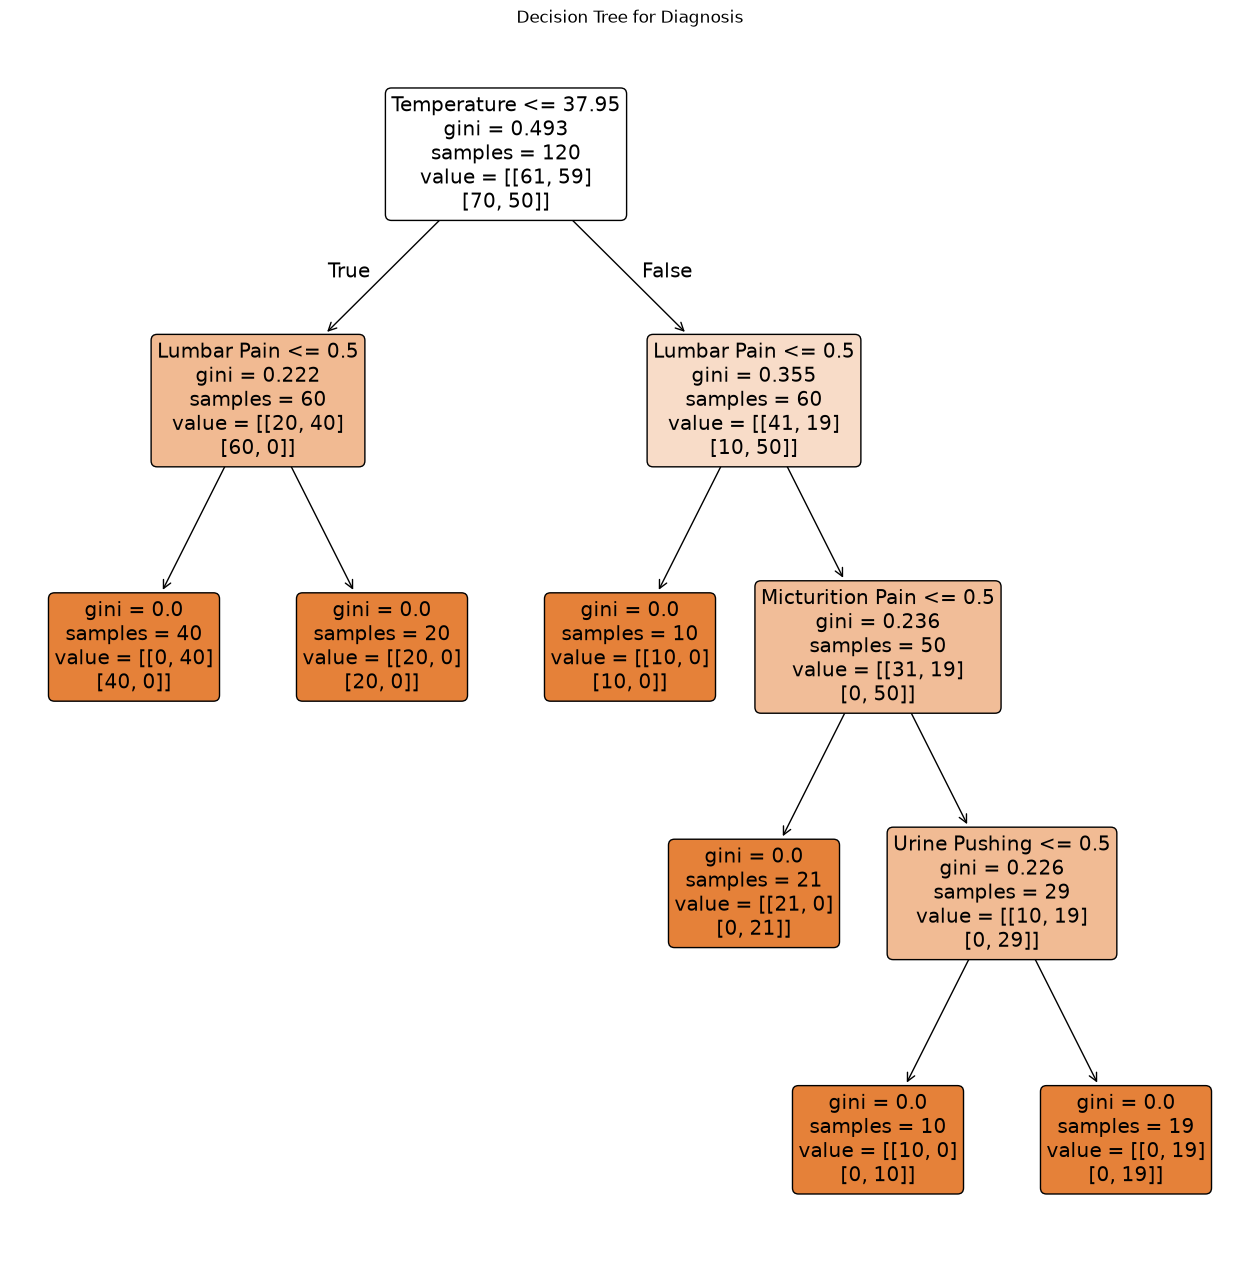

In [9]:
X = df[["Temperature", "Nausea", "Lumbar Pain", "Urine Pushing", "Micturition Pain", "Urethra Burning"]]
y = df[["Bladder Inflammation", "Nephritis"]]

tree = DecisionTreeClassifier(random_state=552)
tree.fit(X, y)
plt.figure(figsize=[16, 16])
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True)
plt.title("Decision Tree for Diagnosis")
plt.show()

### (c) Convert the decision rules

In [22]:
def tree_to_pseudo(tree, feature_names, diagnosis):
    left = tree.tree_.children_left
    right = tree.tree_.children_right
    threshold = tree.tree_.threshold
    features = [feature_names[i] for i in tree.tree_.feature]
    value = tree.tree_.value

    def recurse(node, depth=0):
        ident = " " * depth

        if threshold[node] != -2:

            print(ident + "IF " + features[node] + " <= " + str(round(threshold[node], 2)))

            recurse(left[node], depth + 1)
            print(ident + "ELSE")

            recurse(right[node], depth + 1)
        else:
            prediction = []
            for i, target in enumerate(diagnosis):
                index = value[node][i].argmax()
                pred_class = tree.classes_[i][index]
                result = "Yes" if pred_class == 1 else "No"
                prediction.append(target + " = " + result)

            print(ident + "Then " + ", ".join(prediction))
    recurse(0)

tree_to_pseudo(tree, list(X.columns), y.columns)

IF Temperature <= 37.95
 IF Lumbar Pain <= 0.5
  Then Bladder Inflammation = Yes, Nephritis = No
 ELSE
  Then Bladder Inflammation = No, Nephritis = No
ELSE
 IF Lumbar Pain <= 0.5
  Then Bladder Inflammation = No, Nephritis = No
 ELSE
  IF Micturition Pain <= 0.5
   Then Bladder Inflammation = No, Nephritis = Yes
  ELSE
   IF Urine Pushing <= 0.5
    Then Bladder Inflammation = No, Nephritis = Yes
   ELSE
    Then Bladder Inflammation = Yes, Nephritis = Yes


### (d) Pruning

In [16]:
path = tree.cost_complexity_pruning_path(X,y)

pruned_tree = []
for a in path.ccp_alphas:
    clf = DecisionTreeClassifier(random_state=552, ccp_alpha=a )
    clf.fit(X, y)
    pruned_tree.append(clf)

results = pd.DataFrame({
    "ccp_alpha": path.ccp_alphas,
    "nodes": [clf.tree_.node_count for clf in pruned_tree],
    "leaves": [clf.get_n_leaves() for clf in pruned_tree],
    "depth": [clf.get_depth() for clf in pruned_tree],
    "accuracy": [clf.score(X, y) for clf in pruned_tree],
})
results

,ccp_alpha,nodes,leaves,depth,accuracy
0,0.000000,11,6,4,1.000000
1,0.049083,7,4,2,0.841667
2,0.079472,5,3,2,0.758333
3,0.111111,3,2,1,0.591667
4,0.204236,1,1,0,0.250000


Here we choose the best ccp_alpha = 0.049083, because it reduced the nodes from 11 to 7 and 6 leaves to 4, while maintaining the highest accuracy to other larger ccp_alpha.

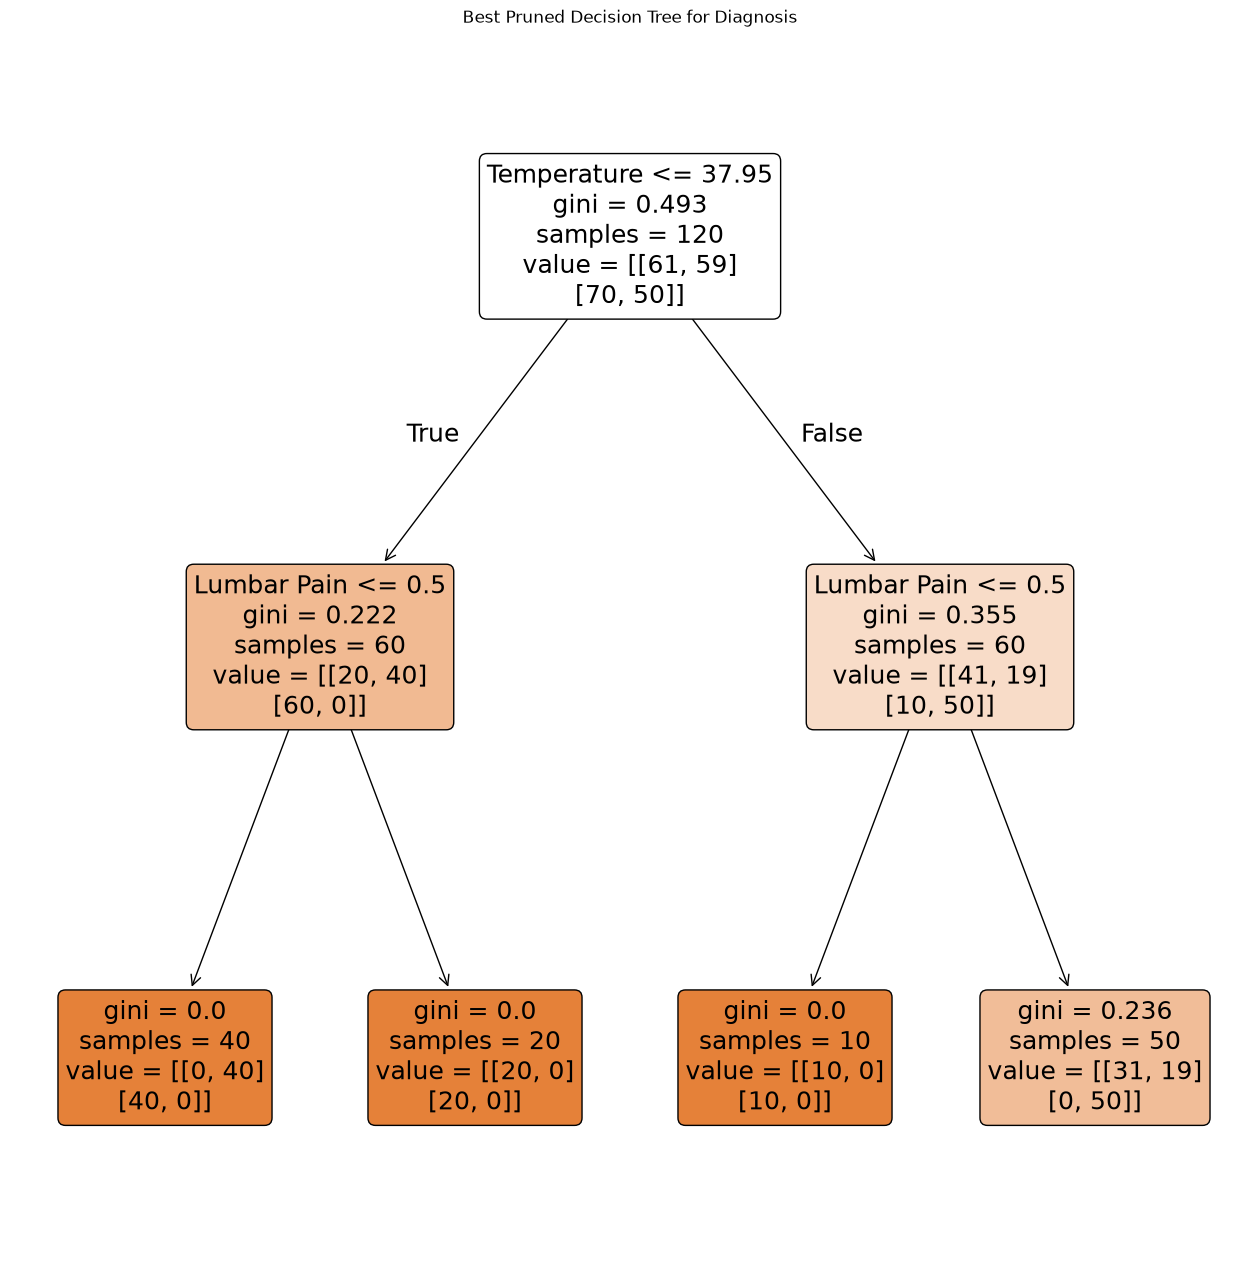

In [19]:
best_ccp_alpha = path.ccp_alphas[1]

final_tree = DecisionTreeClassifier(random_state=552, ccp_alpha=best_ccp_alpha)
final_tree.fit(X, y)

plt.figure(figsize=[16, 16])
plot_tree(final_tree, feature_names=X.columns, filled=True, rounded=True)
plt.title("Best Pruned Decision Tree for Diagnosis")
plt.show()


In [23]:
tree_to_pseudo(final_tree, list(X.columns), y.columns)

IF Temperature <= 37.95
 IF Lumbar Pain <= 0.5
  Then Bladder Inflammation = Yes, Nephritis = No
 ELSE
  Then Bladder Inflammation = No, Nephritis = No
ELSE
 IF Lumbar Pain <= 0.5
  Then Bladder Inflammation = No, Nephritis = No
 ELSE
  Then Bladder Inflammation = No, Nephritis = Yes


## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [33]:
community_df = pd.read_csv("communities.data", header=None, na_values="?")
community_df.head()

,0,1,2,3,4,5,6,7,8,9,...,118,119,120,121,122,123,124,125,126,127
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [34]:
community_df = community_df.drop(columns=[0,1,2,3,4])

In [46]:
X = community_df.iloc[:, :-1]
y = community_df.iloc[:, -1]
X_train = X.iloc[:1495].copy()
X_test = X.iloc[1495:].copy()
y_train = y.iloc[:1495].copy()
y_test = y.iloc[1495:].copy()

imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)
X_train = pd.DataFrame(X_train_imputed, columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(X_test_imputed, columns=X_test.columns, index=X_test.index)



### (c) Plot a correlation matrix

In [48]:
X_imputed = pd.concat([X_train, X_test])
corr = X_imputed.corr()

corr

,5,6,7,8,9,10,11,12,13,14,...,117,118,119,120,121,122,123,124,125,126
5,1.000000,-0.046148,0.231178,-0.300845,0.181603,0.156218,0.006368,0.130344,0.075596,-0.102006,...,0.177954,0.713652,0.231897,0.270356,0.784403,0.742270,-0.210074,-0.003039,0.466352,0.109434
6,-0.046148,1.000000,-0.067109,-0.235907,0.201996,0.468659,0.520461,0.367338,0.295225,-0.612666,...,0.023544,-0.015078,-0.004072,-0.051506,-0.068708,-0.037594,0.020222,0.013576,-0.094368,-0.078196
7,0.231178,-0.067109,1.000000,-0.794389,-0.106738,-0.066581,0.122338,0.153475,0.134068,0.052934,...,-0.023233,0.149758,0.095053,0.147023,0.213639,0.158850,-0.149030,-0.025322,0.260793,0.087642
8,-0.300845,-0.235907,-0.794389,1.000000,-0.270266,-0.444166,-0.194015,-0.266852,-0.183804,0.136483,...,-0.057281,-0.131389,-0.337458,-0.215636,-0.209662,-0.195427,0.125764,0.006167,-0.276234,-0.077442
9,0.181603,0.201996,-0.106738,-0.270266,1.000000,0.266743,-0.025020,0.100727,0.052761,-0.272020,...,0.144554,-0.001084,0.389944,0.296921,0.026387,0.098876,0.001615,0.049272,0.101888,0.017137
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
122,0.742270,-0.037594,0.158850,-0.195427,0.098876,0.098898,-0.019937,0.046732,0.021681,-0.031430,...,0.140746,0.494447,0.201027,0.241816,0.821048,1.000000,-0.157494,-0.016920,0.202379,0.311784
123,-0.210074,0.020222,-0.149030,0.125764,0.001615,-0.012396,0.003271,-0.017292,-0.006703,0.010649,...,-0.007729,-0.163014,-0.012046,-0.045042,-0.197844,-0.157494,1.000000,0.040901,-0.208094,-0.284577
124,-0.003039,0.013576,-0.025322,0.006167,0.049272,0.006880,0.012554,-0.010717,-0.011441,-0.039631,...,0.094728,0.057715,-0.110503,-0.117694,0.022857,-0.016920,0.040901,1.000000,-0.135341,-0.052814
125,0.466352,-0.094368,0.260793,-0.276234,0.101888,0.125353,0.001301,0.117290,0.083180,-0.010168,...,0.065854,0.299632,0.228084,0.206644,0.282930,0.202379,-0.208094,-0.135341,1.000000,0.236636


### (d) Calculate the Coefficient of Variation CV

In [54]:
cv = X_imputed.std(ddof=1) / X_imputed.mean()
cv_table = pd.DataFrame({
    "CV": cv
})
cv_table

,CV
5,2.203503
6,0.353298
7,1.410920
8,0.323782
9,1.359162
...,...
122,1.562900
123,0.117807
124,0.333483
125,2.555266


### (e) Scatter plots and box plots for highest CV features

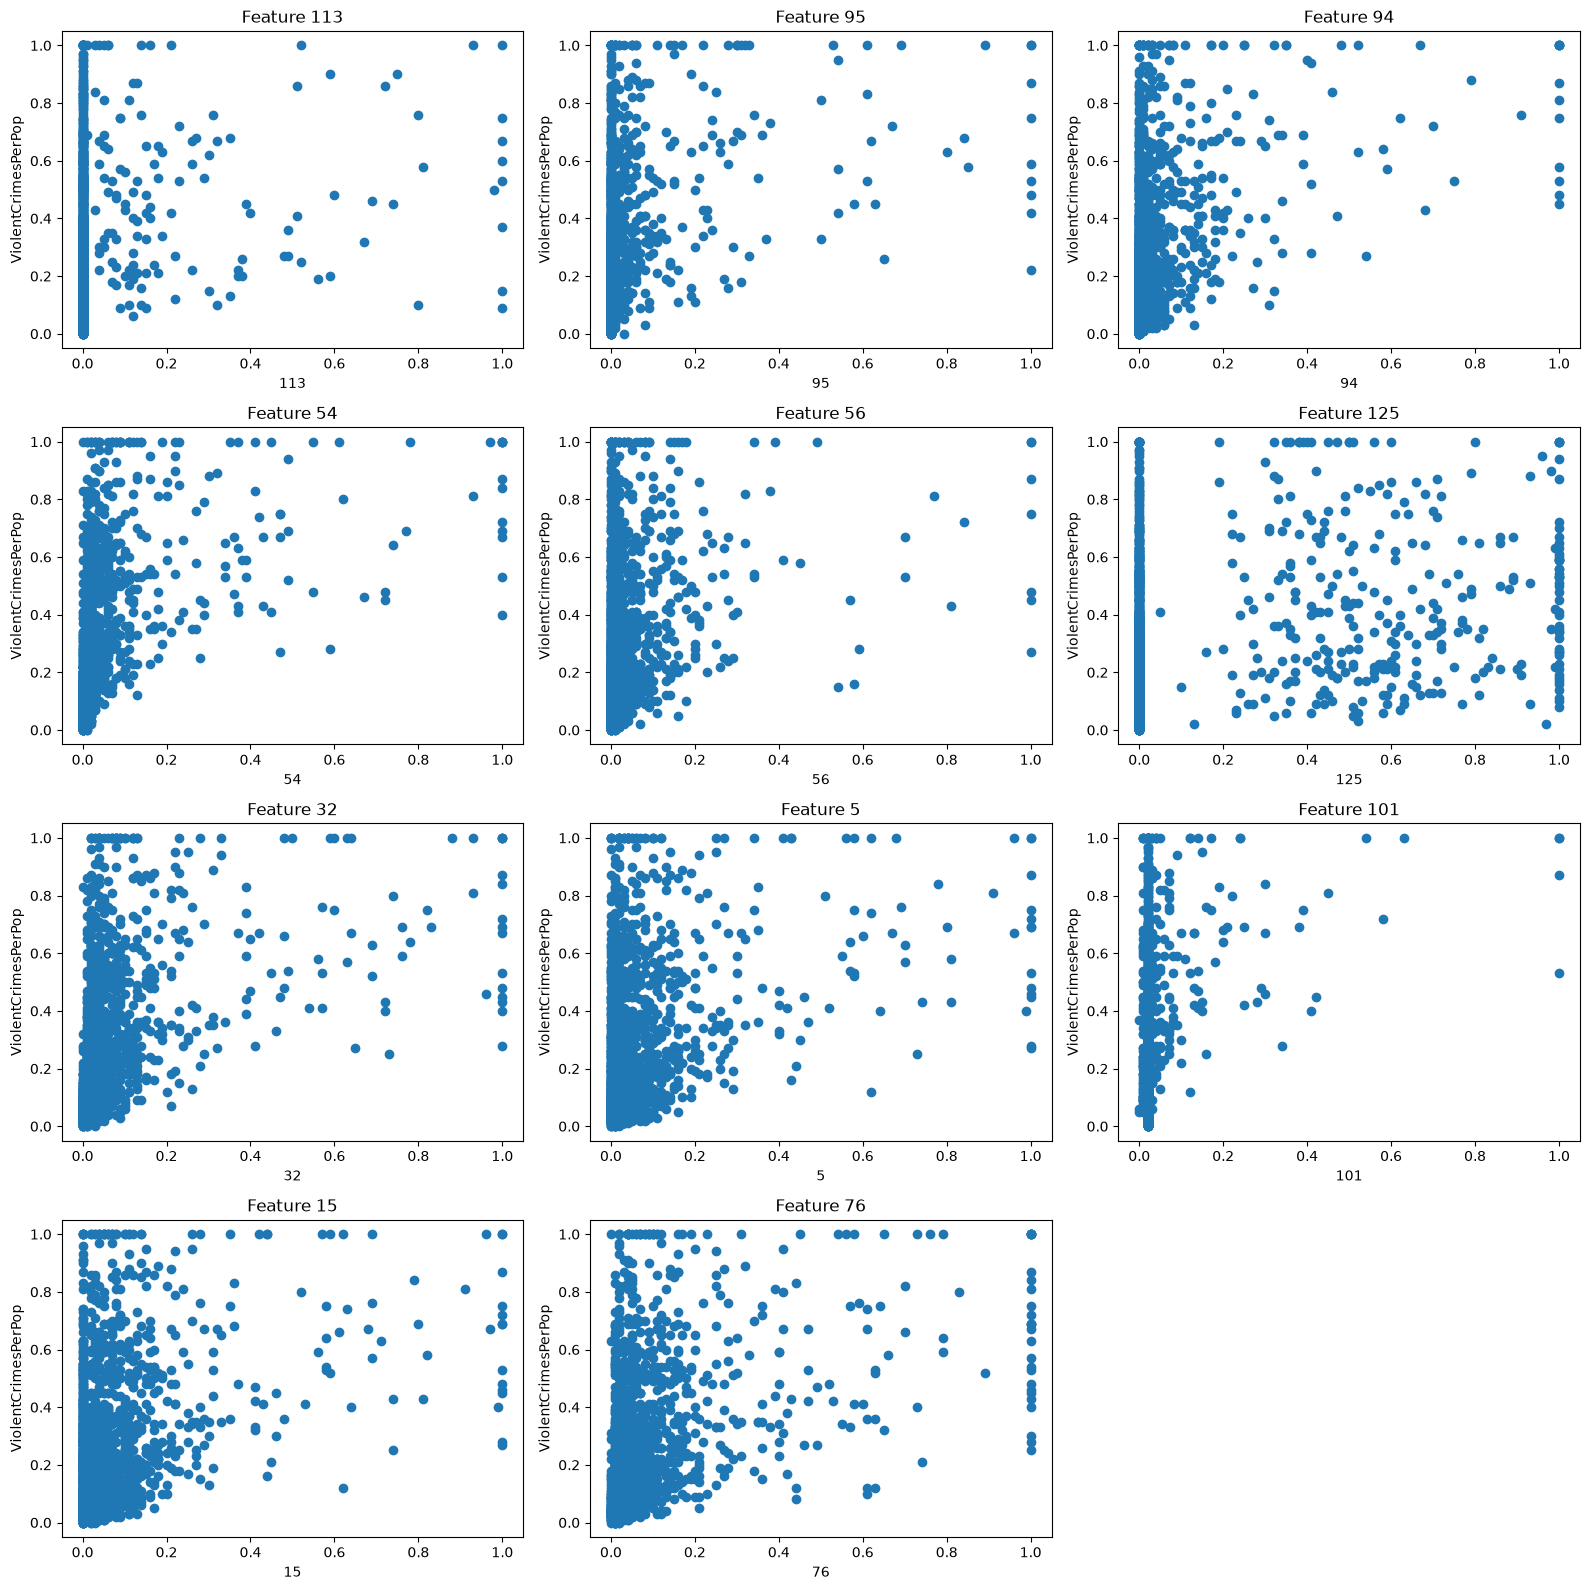

In [60]:
cv_table = cv_table.sort_values(by="CV", ascending=False)
n = int(np.floor(np.sqrt(128)))

selected_features = cv_table.head(n).index

fig, axes = plt.subplots(4,3, figsize=(16, 16))
axes = axes.flatten()
for i, feature in enumerate(selected_features):
    axes[i].scatter(X_imputed[feature], y)
    axes[i].set_title(f"Feature {feature}")
    axes[i].set_xlabel(str(feature))
    axes[i].set_ylabel("ViolentCrimesPerPop")
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

By just looking at our scatter plot, we cannot determine any statistical significance. We can only say some selected features may have some relationships with our y, but we need more, like regression analysis or hypothesis testing, than just scatter plot to rule any statistical relationships.

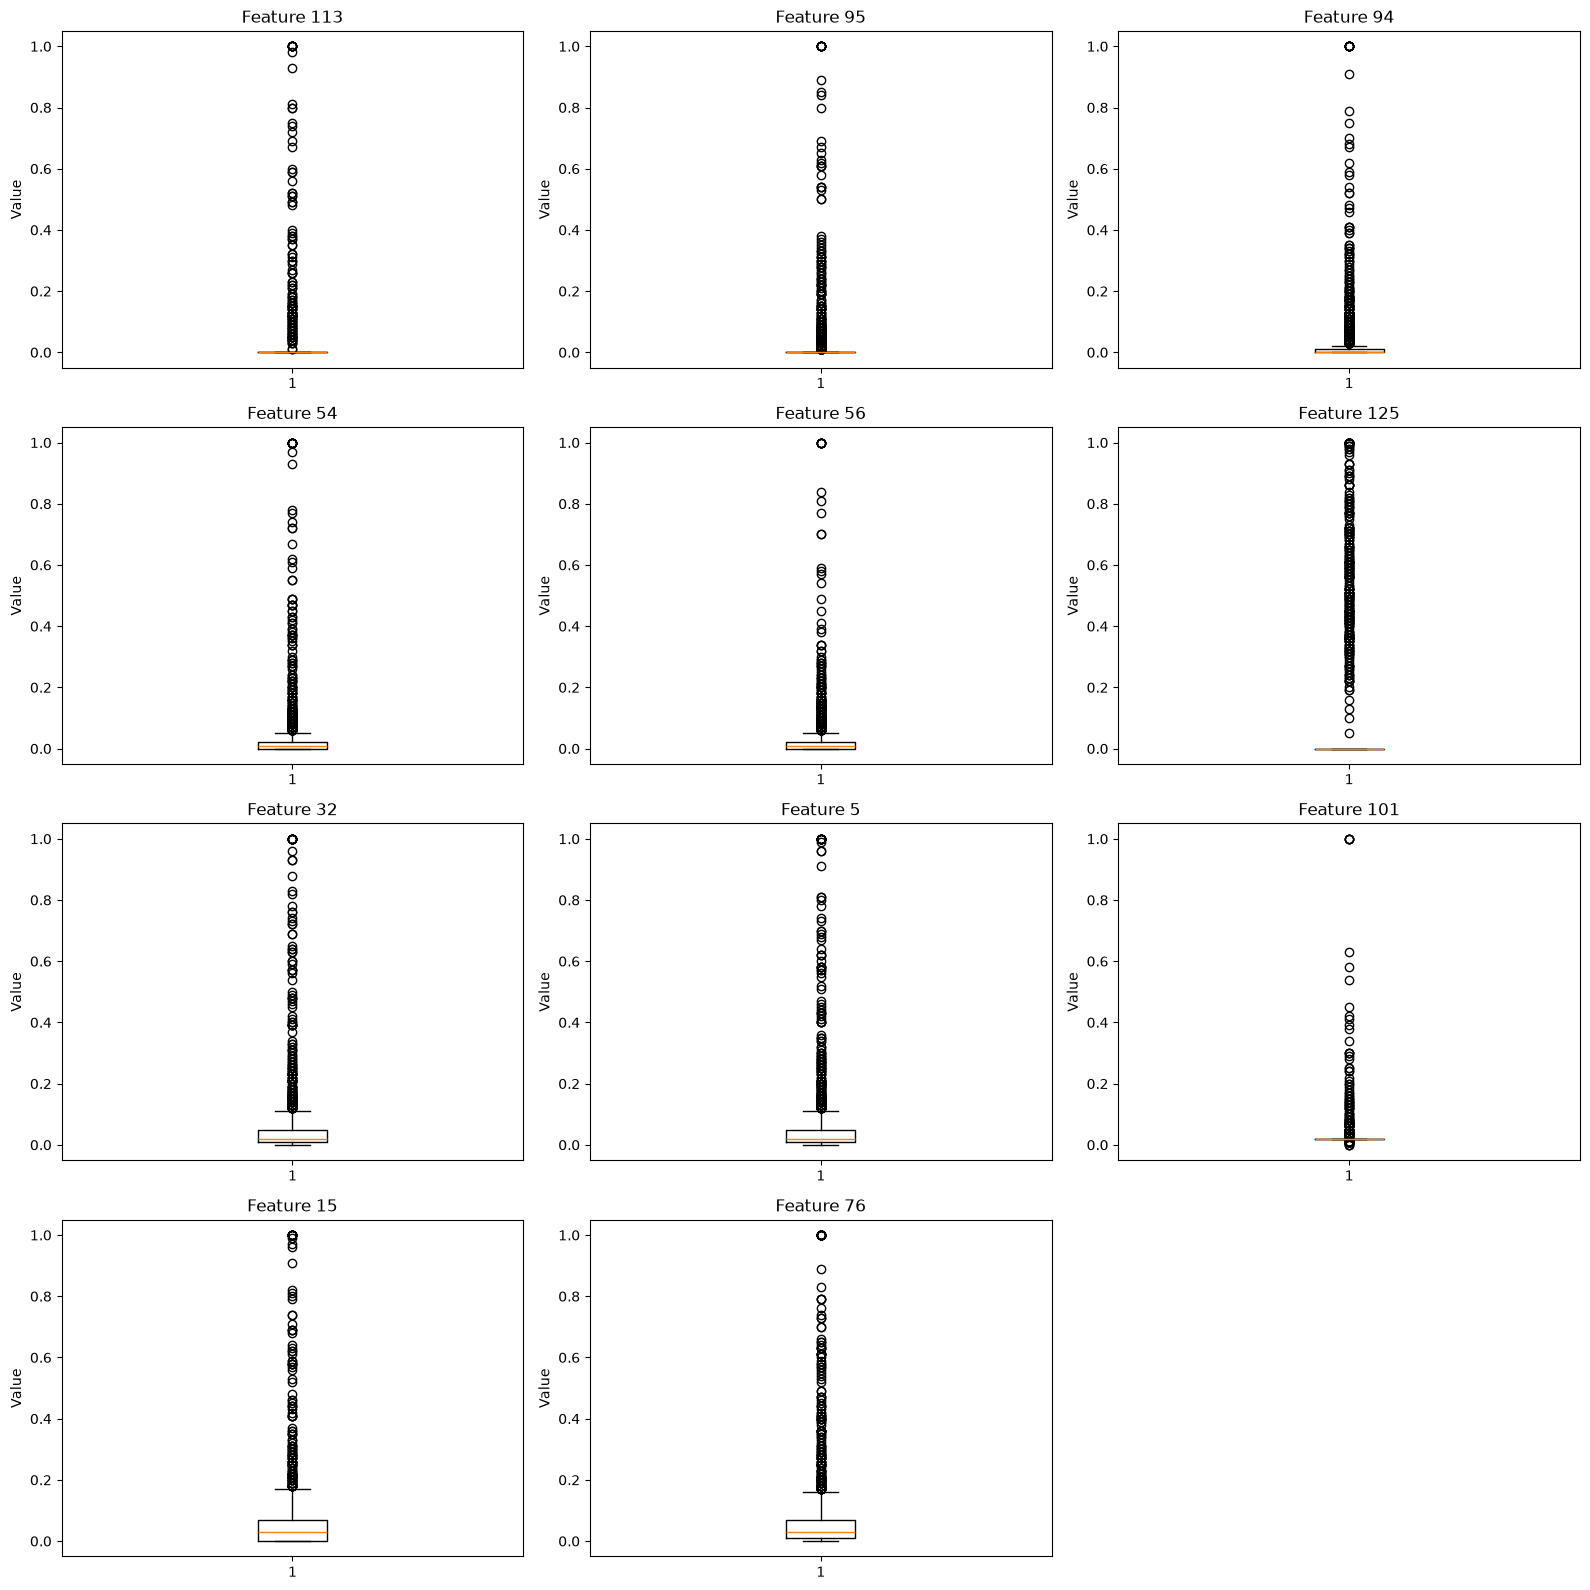

In [63]:
fig, axes = plt.subplots(4,3, figsize=(16, 16))
axes = axes.flatten()
for i, feature in enumerate(selected_features):
    axes[i].boxplot(X_imputed[feature].dropna())
    axes[i].set_title(f"Feature {feature}")
    axes[i].set_ylabel("Value")
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

### (f) Fit a linear model

In [65]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred = linear_model.predict(X_test)
mse  = mean_squared_error(y_test, y_pred)
print("Test MSE: " + str(mse))

Test MSE: 0.017966215426067342


### (g) Fit a ridge regression model

In [70]:
alpha = np.logspace(-4, 4, 100)
scaler = StandardScaler()
X_trained_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
ridge_model = RidgeCV(alphas=alpha, cv=5, scoring="neg_mean_squared_error")
ridge_model.fit(X_trained_scaled, y_train)

ridge_pred = ridge_model.predict(X_test_scaled)
ridge_mse = mean_squared_error(y_test, ridge_pred)

print("Ridge Model Test MSE: " + str(ridge_mse))

Ridge Model Test MSE: 0.017431130507402394


### (h) Fit a LASSO model

In [76]:
lasso = LassoCV(cv=5,random_state=552, max_iter=100000)
lasso.fit(X_train, y_train)
lasso_pred = lasso.predict(X_test)
lasso_mse = mean_squared_error(y_test, lasso_pred)


lasso_scaled = LassoCV(cv=5,random_state=552, max_iter=100000)
lasso_scaled.fit(X_trained_scaled, y_train)
lasso_scaled_pred = lasso_scaled.predict(X_test_scaled)
lasso_scaled_mse = mean_squared_error(y_test, lasso_scaled_pred)

print("Lasso Model Test MSE: " + str(lasso_mse))
print("Standardized Lasso Model Test MSE: " + str(lasso_scaled_mse))

lasso_selected_features = X_train.columns[lasso.coef_ !=0]
lasso_scaled_selected_features = X_train.columns[lasso_scaled.coef_ != 0]
print("Lasso Selected Features: " )
print(list(lasso_selected_features))
print("Standardized Lasso Selected Features: " )
print(list(lasso_scaled_selected_features))

Lasso Model Test MSE: 0.017617760569778627
Standardized Lasso Model Test MSE: 0.01768200098674982
Lasso Selected Features: 
[7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 41, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 57, 60, 64, 66, 68, 69, 72, 73, 74, 75, 76, 77, 79, 80, 81, 82, 83, 84, 87, 90, 91, 92, 93, 94, 95, 96, 97, 99, 104, 107, 109, 111, 112, 113, 116, 117, 118, 119, 120, 121, 123, 124]
Standardized Lasso Selected Features: 
[7, 9, 11, 12, 16, 18, 19, 20, 21, 22, 23, 26, 27, 28, 29, 30, 31, 33, 34, 38, 39, 43, 44, 45, 49, 50, 51, 53, 54, 55, 56, 58, 60, 64, 66, 68, 69, 72, 73, 74, 76, 77, 79, 80, 81, 82, 83, 87, 90, 91, 92, 93, 94, 95, 96, 99, 104, 105, 107, 109, 111, 112, 113, 115, 116, 117, 118, 119, 120, 121, 123, 124]


The non-standardized Lasso model performs a little bit better than the standardized one. Here it looks reasonable because our original dataset is already normalized, so standardization did not improve much on the test performance.

### (i) Fit a PCR model

In [82]:
components = X_trained_scaled.shape[1]
cv =KFold(n_splits=5, shuffle=True, random_state=552)
cv_mse = []
for m in range (1, components + 1):
    pca = PCA(n_components=m)
    X_train_pca = pca.fit_transform(X_trained_scaled)
    model = LinearRegression()
    scores = cross_val_score(model, X_train_pca, y_train, cv=cv, scoring="neg_mean_squared_error")
    cv_mse.append(-scores.mean())

best_m = np.argmin(cv_mse)+1
print("Best number of principal components: " + str(best_m))
print("Best CV MSE: " + str(cv_mse[best_m-1]))

pca_final = PCA(n_components=best_m)
X_train_pca = pca_final.fit_transform(X_train)
X_test_pca = pca_final.transform(X_test)

pcr_model = LinearRegression()
pcr_model.fit(X_train_pca, y_train)
pcr_pred = pcr_model.predict(X_test_pca)
pcr_mse = mean_squared_error(y_test, pcr_pred)
print("PCR Model Test MSE: " + str(pcr_mse))

Best number of principal components: 93
Best CV MSE: 0.019448657070721357
PCR Model Test MSE: 0.01835558026457276


### (j) Fit a boosting tree

In [84]:
alphas = np.logspace(-4, 4, 100)

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    n_estimators=300,
    learning_rate=0.1,
    max_depth=5,
    random_state=552,
)

grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid={"reg_alpha": alphas},
    scoring="neg_mean_squared_error",
    cv=5
)
grid_search.fit(X_train, y_train)
print("Best alpha: ", grid_search.best_params_["reg_alpha"])

best_xgb = grid_search.best_estimator_
xgb_pred = best_xgb.predict(X_test)
xgb_mse = mean_squared_error(y_test, xgb_pred)
print("XGB Model Test MSE: " + str(xgb_mse))

Best alpha:  0.6280291441834259
XGB Model Test MSE: 0.0162663610413026
